In [2]:
!pip install landingai opencv-python pillow matplotlib gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 28.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of opencv-python-headless to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 27.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 57.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 63.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 51.1 MB/

In [3]:
from getpass import getpass
from landingai.predict import Predictor

ENDPOINT_ID = input("Enter your LandingLens Endpoint ID: ")
API_KEY = getpass("Enter your LandingLens API Key: ")

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingLens model connected successfully!")

Enter your LandingLens Endpoint ID: 83b05ec6-b11d-4dcd-ab47-c141e22bad28
Enter your LandingLens API Key: ··········
LandingLens model connected successfully!


Saving test_image.webp to test_image.webp


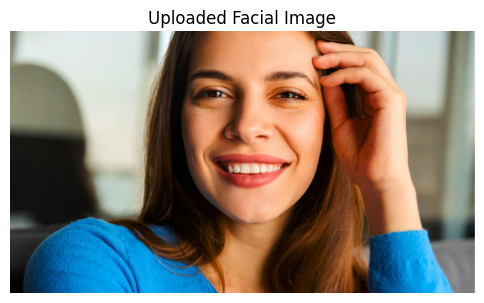

In [4]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Facial Image")
plt.show()

In [5]:
from importlib.metadata import version, PackageNotFoundError

for package in ["landingai", "Pillow"]:
    try:
        print(package, ":", version(package))
    except PackageNotFoundError:
        print(package, "not found")

landingai : 0.3.49
Pillow : 10.4.0


In [11]:
import cv2
import requests

image = cv2.imread(image_path)

success, encoded_image = cv2.imencode(".jpg", image)

if not success:
    raise ValueError("Could not encode image")

print("Image encoded successfully:", len(encoded_image))

Image encoded successfully: 215536


In [12]:
import requests
from getpass import getpass

endpoint_id = input("Enter Endpoint ID: ").strip()
api_key = getpass("Enter LandingAI API Key: ")

url = "https://predict.app.landing.ai/inference/v1/predict"

files = {
    "file": ("image.jpg", encoded_image.tobytes(), "image/jpeg")
}

headers = {
    "apikey": api_key
}

response = requests.post(
    url,
    params={"endpoint_id": endpoint_id},
    headers=headers,
    files=files
)

print("Status:", response.status_code)
print("Response:")
print(response.text)

Enter Endpoint ID: 83b05ec6-b11d-4dcd-ab47-c141e22bad28
Enter LandingAI API Key: ··········
Status: 200
Response:
{"backbonetype":null,"backbonepredictions":null,"predictions":{"score":0.32735687494277954,"labelName":"Happy","labelIndex":4},"type":"ClassificationPrediction","latency":{"preprocess_s":0.004706382751464844,"infer_s":0.15177464485168457,"postprocess_s":0.0000743865966796875,"serialize_s":0.00009179115295410156,"input_conversion_s":0.007881879806518555,"model_loading_s":5.185177803039551},"model_id":"bd7bd65b-916a-4b7c-a80f-d47fa6e80c7b"}


Saving test_image.webp to test_image (1).webp


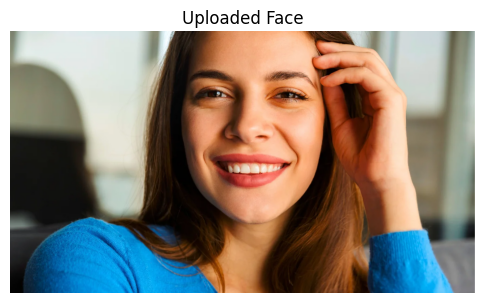


# Emotion Detection Result

## Happy

**Confidence:** 32.74%

The model classified the facial expression as **Happy**.


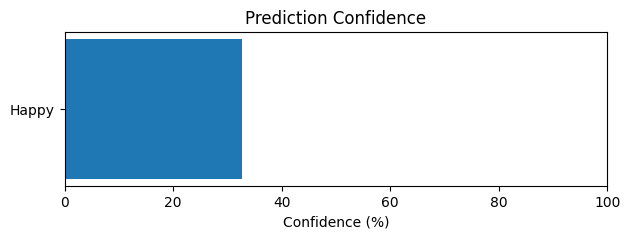

In [14]:
import requests
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Markdown

uploaded = files.upload()

image_path = next(iter(uploaded))

image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

success, encoded = cv2.imencode(".jpg", image)

files_data = {
    "file": ("image.jpg", encoded.tobytes(), "image/jpeg")
}

response = requests.post(
    "https://predict.app.landing.ai/inference/v1/predict",
    params={"endpoint_id": endpoint_id},
    headers={"apikey": api_key},
    files=files_data
)

result = response.json()["predictions"]

emotion = result["labelName"]
confidence = result["score"] * 100

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Uploaded Face")
plt.show()

display(Markdown(f"""
# Emotion Detection Result

## {emotion}

**Confidence:** {confidence:.2f}%

The model classified the facial expression as **{emotion}**.
"""))

plt.figure(figsize=(7, 2))
plt.barh([emotion], [confidence])
plt.xlim(0, 100)
plt.xlabel("Confidence (%)")
plt.title("Prediction Confidence")
plt.show()